In [18]:
import pandas as pd
path = "https://raw.githubusercontent.com/ulka29/paper/7aad80ab3fe4ad5ffeabffb7c30bcb70edb218bd/01_data/processed/df_cleaned.csv"# import Check dataset
df= pd.read_csv(path)
df.head()

,tweet_text,cyberbullying_type,clean_tweet,lemmatized_tweet,sentiment_scores,negative,positive,neutral,compound
0,"in other words #katandandre, your food was cra...",not_cyberbullying,words katandandre food crapilicious mkr,word katandandre food crapilicious mkr,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
1,why is #aussietv so white? #mkr #theblock #ima...,not_cyberbullying,aussietv white mkr theblock imacelebrityau tod...,aussietv white mkr theblock imacelebrityau tod...,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
2,@xochitlsuckkks a classy whore? or more red ve...,not_cyberbullying,classy whore red velvet cupcakes,classy whore red velvet cupcake,"{'neg': 0.32, 'neu': 0.481, 'pos': 0.199, 'com...",0.320,0.199,0.481,-0.4137
3,"@jason_gio meh. :p thanks for the heads up, b...",not_cyberbullying,meh p thanks heads concerned another angry dud...,meh p thanks head concerned another angry dude...,"{'neg': 0.243, 'neu': 0.607, 'pos': 0.15, 'com...",0.243,0.150,0.607,-0.4854
4,@rudhoeenglish this is an isis account pretend...,not_cyberbullying,isis account pretending kurdish account like i...,isi account pretending kurdish account like is...,"{'neg': 0.129, 'neu': 0.691, 'pos': 0.18, 'com...",0.129,0.180,0.691,0.0258


In [19]:
# Select relevant features for SA + ML
df_ml = df[
    [
        'lemmatized_tweet',
        'negative',
        'positive',
        'neutral',
        'compound',
        'cyberbullying_type'
    ]
].copy()

# Check shape
print("\n:-------------Shape::-------------", df_ml.shape)

# Check column names
print("\n:-------------Columns::-------------")
print(df_ml.columns.tolist())

# Check missing values
print("\n----------------Missing values:-------------")
print(df_ml.isnull().sum())

# Display first 5 rows
df_ml.head()


:-------------Shape::------------- (42645, 6)

:-------------Columns::-------------
['lemmatized_tweet', 'negative', 'positive', 'neutral', 'compound', 'cyberbullying_type']

----------------Missing values:-------------
lemmatized_tweet      30
negative               0
positive               0
neutral                0
compound               0
cyberbullying_type     0
dtype: int64


,lemmatized_tweet,negative,positive,neutral,compound,cyberbullying_type
0,word katandandre food crapilicious mkr,0.000,0.000,1.000,0.0000,not_cyberbullying
1,aussietv white mkr theblock imacelebrityau tod...,0.000,0.000,1.000,0.0000,not_cyberbullying
2,classy whore red velvet cupcake,0.320,0.199,0.481,-0.4137,not_cyberbullying
3,meh p thanks head concerned another angry dude...,0.243,0.150,0.607,-0.4854,not_cyberbullying
4,isi account pretending kurdish account like is...,0.129,0.180,0.691,0.0258,not_cyberbullying


In [20]:
df = df[df["cyberbullying_type"] != "not_cyberbullying"].reset_index(drop=True)

## Original penta-class task; negative-polarity filtering as in the paper

In [21]:

# ============================================================
# CELL 1: DATA PREPARATION
# PENTA CLASS + WORD TF-IDF + SENTIMENT FEATURES
# NEGATIVE POLARITY ONLY (COMPOUND < 0)
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# ------------------------------------------------------------
# 0. FILTER DATASET: NEGATIVE POLARITY ONLY
# ------------------------------------------------------------

original_size = len(df)
df = df.loc[df['compound'] < 0].copy()

print("Original dataset size:", original_size)
print("Dataset size after filtering:", len(df))
print("Removed tweets:", original_size - len(df))

# ------------------------------------------------------------
# 1. TEXT, SENTIMENT FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df['lemmatized_tweet'].fillna('')

sentiment_features = [
    'negative',
    'positive',
    'neutral',
    'compound'
]

X_sentiment = df[sentiment_features].fillna(0)
y = df['cyberbullying_type']

# ------------------------------------------------------------
# 2. LABEL ENCODING
# ------------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nClasses:")
print(label_encoder.classes_)

label_mapping = dict(enumerate(label_encoder.classes_))

print("\nLabel Mapping:")
for number, category in label_mapping.items():
    print(f"{number} -> {category}")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

(
    X_text_train,
    X_text_test,
    X_sent_train,
    X_sent_test,
    y_train,
    y_test
) = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split")
print("-------------------------")
print("Training samples:", len(X_text_train))
print("Testing samples :", len(X_text_test))

# ------------------------------------------------------------
# 4. WORD TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nWord TF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_sent_train_sparse = csr_matrix(
    X_sent_train.to_numpy(dtype=float)
)

X_sent_test_sparse = csr_matrix(
    X_sent_test.to_numpy(dtype=float)
)

X_train_combined = hstack(
    [X_train_tfidf, X_sent_train_sparse],
    format='csr'
)

X_test_combined = hstack(
    [X_test_tfidf, X_sent_test_sparse],
    format='csr'
)

print("\nCombined Features: Word TF-IDF + Sentiment")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)


Original dataset size: 36200
Dataset size after filtering: 25157
Removed tweets: 11043

Classes:
['age' 'ethnicity' 'gender' 'other_cyberbullying' 'religion']

Label Mapping:
0 -> age
1 -> ethnicity
2 -> gender
3 -> other_cyberbullying
4 -> religion

Train-Test Split
-------------------------
Training samples: 17609
Testing samples : 7548

Word TF-IDF Features
-------------------------
X_train TF-IDF: (17609, 10000)
X_test TF-IDF : (7548, 10000)

Combined Features: Word TF-IDF + Sentiment
-------------------------
X_train: (17609, 10004)
X_test : (7548, 10004)


In [22]:

# ============================================================
# Penta class + WORD TF-IDF + SA + No Balancing + Logistic Regression
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITH FIXED HYPERPARAMETERS
# ------------------------------------------------------------

lr_none = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA (NO BALANCING)
# ------------------------------------------------------------

print("Training SA + No Balancing + Logistic Regression...")

lr_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. BEST MODEL (FIXED C; NO GRID SEARCH)
# ------------------------------------------------------------

best_none = lr_none

print("\nFixed Parameters:")
print(best_none.get_params())

# ------------------------------------------------------------
# 4. PREDICTION
# ------------------------------------------------------------

y_pred_none = best_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

none_accuracy = accuracy_score(
    y_test,
    y_pred_none
)

none_weighted_f1 = f1_score(
    y_test,
    y_pred_none,
    average='weighted'
)

none_macro_f1 = f1_score(
    y_test,
    y_pred_none,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("NO BALANCING + LOGISTIC REGRESSION (C=1)")
print("==============================================")

print(f"Accuracy     : {none_accuracy:.4f}")
print(f"Weighted F1  : {none_weighted_f1:.4f}")
print(f"Macro F1     : {none_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_none,
        target_names=label_encoder.classes_
    )
)


Training SA + No Balancing + Logistic Regression...

Fixed Parameters:
{'C': 1, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

NO BALANCING + LOGISTIC REGRESSION (C=1)
Accuracy     : 0.9540
Weighted F1  : 0.9548
Macro F1     : 0.9396

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.98      0.98      0.98      1782
          ethnicity       0.99      0.98      0.99      1847
             gender       0.96      0.91      0.93      1522
other_cyberbullying       0.78      0.87      0.82       790
           religion       0.98      0.97      0.98      1607

           accuracy                           0.95      7548
          macro avg       0.94      0.94      0.94      7548
  

## Hexa-class task; same negative-polarity filtering

In [23]:

# ============================================================
# CELL 1: DATA PREPARATION
# HEXA CLASS + WORD TF-IDF + SENTIMENT FEATURES
# NEGATIVE POLARITY ONLY (COMPOUND < 0)
# SOURCE DATASET: df_ml (UNCHANGED)
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# ------------------------------------------------------------
# 0. CREATE COPY: NEGATIVE POLARITY ONLY
# ------------------------------------------------------------

original_size = len(df_ml)

df_negative = df_ml.loc[df_ml['compound'] < 0].copy()

print("Original hexaclass dataset size:", original_size)
print("Negative-polarity dataset size:", len(df_negative))
print("Removed tweets:", original_size - len(df_negative))

print("\nClass distribution after filtering:")
print(df_negative['cyberbullying_type'].value_counts())

# ------------------------------------------------------------
# 1. TEXT, SENTIMENT FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df_negative['lemmatized_tweet'].fillna('')

sentiment_features = [
    'negative',
    'positive',
    'neutral',
    'compound'
]

X_sentiment = df_negative[sentiment_features].fillna(0)
y = df_negative['cyberbullying_type']

# ------------------------------------------------------------
# 2. LABEL ENCODING
# ------------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nClasses:")
print(label_encoder.classes_)

label_mapping = dict(enumerate(label_encoder.classes_))

print("\nLabel Mapping:")
for number, category in label_mapping.items():
    print(f"{number} -> {category}")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

(
    X_text_train,
    X_text_test,
    X_sent_train,
    X_sent_test,
    y_train,
    y_test
) = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split")
print("-------------------------")
print("Training samples:", len(X_text_train))
print("Testing samples :", len(X_text_test))

# ------------------------------------------------------------
# 4. WORD TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nWord TF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_sent_train_sparse = csr_matrix(
    X_sent_train.to_numpy(dtype=float)
)

X_sent_test_sparse = csr_matrix(
    X_sent_test.to_numpy(dtype=float)
)

X_train_combined = hstack(
    [X_train_tfidf, X_sent_train_sparse],
    format='csr'
)

X_test_combined = hstack(
    [X_test_tfidf, X_sent_test_sparse],
    format='csr'
)

print("\nCombined Features: Word TF-IDF + Sentiment")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)

# Confirm the original dataset was not modified
print("\nOriginal df_ml size (unchanged):", len(df_ml))


Original hexaclass dataset size: 42645
Negative-polarity dataset size: 27708
Removed tweets: 14937

Class distribution after filtering:
cyberbullying_type
ethnicity              6157
age                    5939
religion               5356
gender                 5071
other_cyberbullying    2634
not_cyberbullying      2551
Name: count, dtype: int64

Classes:
['age' 'ethnicity' 'gender' 'not_cyberbullying' 'other_cyberbullying'
 'religion']

Label Mapping:
0 -> age
1 -> ethnicity
2 -> gender
3 -> not_cyberbullying
4 -> other_cyberbullying
5 -> religion

Train-Test Split
-------------------------
Training samples: 19395
Testing samples : 8313

Word TF-IDF Features
-------------------------
X_train TF-IDF: (19395, 10000)
X_test TF-IDF : (8313, 10000)

Combined Features: Word TF-IDF + Sentiment
-------------------------
X_train: (19395, 10004)
X_test : (8313, 10004)

Original df_ml size (unchanged): 42645


Training Word TF-IDF + No Balancing + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42

WORD TF-IDF ONLY + NO BALANCING + LR
Accuracy     : 0.8850
Weighted F1  : 0.8841
Macro F1     : 0.8286

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.98      0.97      1782
          ethnicity       0.98      0.99      0.98      1847
             gender       0.93      0.88      0.90      1522
  not_cyberbullying       0.57      0.52      0.54       765
other_cyberbullying       0.61      0.65      0.63       790
           religion       0.94      0.96      0.95      1607

           accuracy                           0.88      8313
          macro avg       0.83      0.83      0.83      8313
       weighted avg       0.88      0.88      0.88      8313



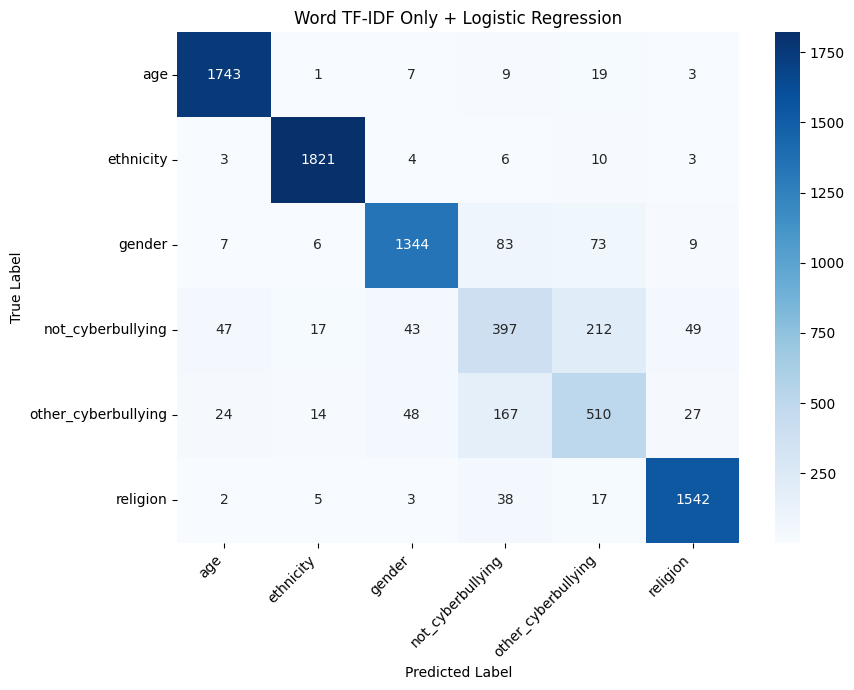

In [24]:

# ============================================================
# Hexa class + WORD TF-IDF ONLY + negetive polarity only
# NO BALANCING + LOGISTIC REGRESSION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ------------------------------------------------------------
# 1. MODEL WITH FIXED HYPERPARAMETERS
# ------------------------------------------------------------

lr_tfidf = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN
# ------------------------------------------------------------

print("Training Word TF-IDF + No Balancing + Logistic Regression...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")

lr_tfidf.fit(X_train_tfidf, y_train)

# ------------------------------------------------------------
# 3. TEST PREDICTION
# ------------------------------------------------------------

best_tfidf = lr_tfidf
y_pred_tfidf = best_tfidf.predict(X_test_tfidf)

# ------------------------------------------------------------
# 4. EVALUATION
# ------------------------------------------------------------

tfidf_accuracy = accuracy_score(y_test, y_pred_tfidf)

tfidf_weighted_f1 = f1_score(
    y_test, y_pred_tfidf, average='weighted'
)

tfidf_macro_f1 = f1_score(
    y_test, y_pred_tfidf, average='macro'
)

print("\n==============================================")
print("WORD TF-IDF ONLY + NO BALANCING + LR")
print("==============================================")
print(f"Accuracy     : {tfidf_accuracy:.4f}")
print(f"Weighted F1  : {tfidf_weighted_f1:.4f}")
print(f"Macro F1     : {tfidf_macro_f1:.4f}")

# ------------------------------------------------------------
# 5. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(classification_report(
    y_test,
    y_pred_tfidf,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm_tfidf = confusion_matrix(
    y_test,
    y_pred_tfidf,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Word TF-IDF Only + Logistic Regression')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Hexa-class task; retain all polarity statements

In [25]:
# ============================================================
# CELL 1: DATA PREPARATION
# WORD TF-IDF + SENTIMENT FEATURES
# DATASET: df_ml
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# ------------------------------------------------------------
# 1. TEXT, SENTIMENT FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df_ml['lemmatized_tweet'].fillna('')

sentiment_features = [
    'negative',
    'positive',
    'neutral',
    'compound'
]

X_sentiment = df_ml[sentiment_features].fillna(0)
y = df_ml['cyberbullying_type']

# ------------------------------------------------------------
# 2. LABEL ENCODING
# ------------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nClasses:")
print(label_encoder.classes_)

label_mapping = dict(enumerate(label_encoder.classes_))

print("\nLabel Mapping:")
for number, category in label_mapping.items():
    print(f"{number} -> {category}")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

(
    X_text_train,
    X_text_test,
    X_sent_train,
    X_sent_test,
    y_train,
    y_test
) = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split")
print("-------------------------")
print("Training samples:", len(X_text_train))
print("Testing samples :", len(X_text_test))

# ------------------------------------------------------------
# 4. WORD TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nWord TF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_sent_train_sparse = csr_matrix(
    X_sent_train.to_numpy(dtype=float)
)

X_sent_test_sparse = csr_matrix(
    X_sent_test.to_numpy(dtype=float)
)

X_train_combined = hstack(
    [X_train_tfidf, X_sent_train_sparse],
    format='csr'
)

X_test_combined = hstack(
    [X_test_tfidf, X_sent_test_sparse],
    format='csr'
)

print("\nCombined Features: Word TF-IDF + Sentiment")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)



Classes:
['age' 'ethnicity' 'gender' 'not_cyberbullying' 'other_cyberbullying'
 'religion']

Label Mapping:
0 -> age
1 -> ethnicity
2 -> gender
3 -> not_cyberbullying
4 -> other_cyberbullying
5 -> religion

Train-Test Split
-------------------------
Training samples: 29851
Testing samples : 12794

Word TF-IDF Features
-------------------------
X_train TF-IDF: (29851, 10000)
X_test TF-IDF : (12794, 10000)

Combined Features: Word TF-IDF + Sentiment
-------------------------
X_train: (29851, 10004)
X_test : (12794, 10004)


### Without sentiment

Training Word TF-IDF + No Balancing + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42

WORD TF-IDF ONLY + NO BALANCING + LR
Accuracy     : 0.8487
Weighted F1  : 0.8497
Macro F1     : 0.8298

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.88      2248
  not_cyberbullying       0.60      0.63      0.61      1934
other_cyberbullying       0.59      0.59      0.59      1608
           religion       0.96      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



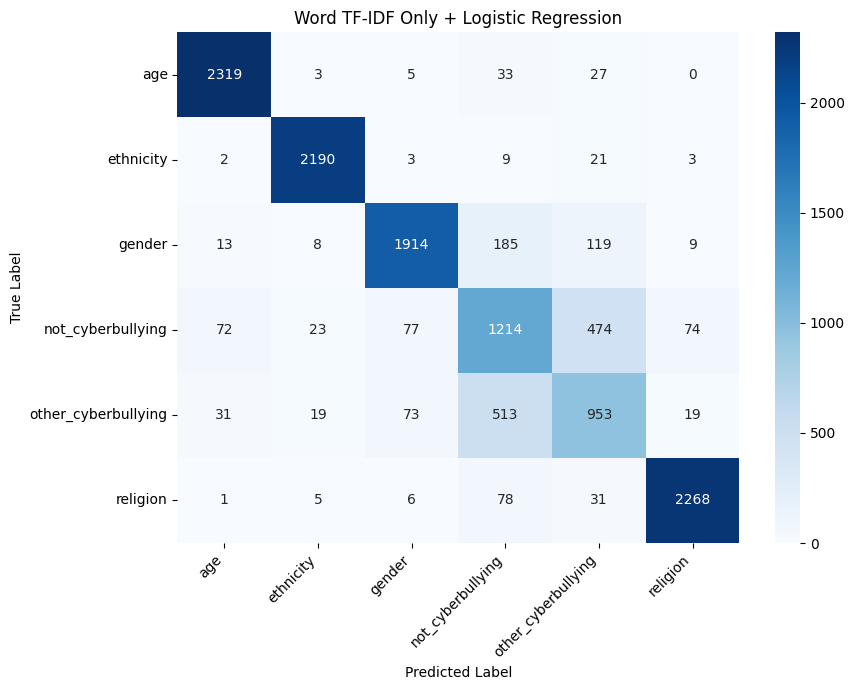

In [26]:

# ============================================================
# Hexa class + WORD TF-IDF ONLY
# NO BALANCING + LOGISTIC REGRESSION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ------------------------------------------------------------
# 1. MODEL WITH FIXED HYPERPARAMETERS
# ------------------------------------------------------------

lr_tfidf = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN
# ------------------------------------------------------------

print("Training Word TF-IDF + No Balancing + Logistic Regression...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")

lr_tfidf.fit(X_train_tfidf, y_train)

# ------------------------------------------------------------
# 3. TEST PREDICTION
# ------------------------------------------------------------

best_tfidf = lr_tfidf
y_pred_tfidf = best_tfidf.predict(X_test_tfidf)

# ------------------------------------------------------------
# 4. EVALUATION
# ------------------------------------------------------------

tfidf_accuracy = accuracy_score(y_test, y_pred_tfidf)

tfidf_weighted_f1 = f1_score(
    y_test, y_pred_tfidf, average='weighted'
)

tfidf_macro_f1 = f1_score(
    y_test, y_pred_tfidf, average='macro'
)

print("\n==============================================")
print("WORD TF-IDF ONLY + NO BALANCING + LR")
print("==============================================")
print(f"Accuracy     : {tfidf_accuracy:.4f}")
print(f"Weighted F1  : {tfidf_weighted_f1:.4f}")
print(f"Macro F1     : {tfidf_macro_f1:.4f}")

# ------------------------------------------------------------
# 5. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(classification_report(
    y_test,
    y_pred_tfidf,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm_tfidf = confusion_matrix(
    y_test,
    y_pred_tfidf,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Word TF-IDF Only + Logistic Regression')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### With sentiment

In [27]:

# ============================================================
# hexa class + WORD TF-IDF + SENTIMENT ANALYSIS
# NO BALANCING + LOGISTIC REGRESSION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# ------------------------------------------------------------
# 1. MODEL WITH FIXED HYPERPARAMETERS
# ------------------------------------------------------------

lr_none = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL, UNBALANCED DATA
# ------------------------------------------------------------

print("Training Word TF-IDF + Sentiment + No Balancing + LR...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")

lr_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. BEST MODEL
# ------------------------------------------------------------

best_none = lr_none

# ------------------------------------------------------------
# 4. TEST PREDICTION
# ------------------------------------------------------------

y_pred_none = best_none.predict(X_test_combined)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

none_accuracy = accuracy_score(y_test, y_pred_none)

none_weighted_f1 = f1_score(
    y_test, y_pred_none, average='weighted'
)

none_macro_f1 = f1_score(
    y_test, y_pred_none, average='macro'
)

print("\n==============================================")
print("WORD TF-IDF + SENTIMENT + NO BALANCING + LR")
print("==============================================")

print(f"Accuracy     : {none_accuracy:.4f}")
print(f"Weighted F1  : {none_weighted_f1:.4f}")
print(f"Macro F1     : {none_macro_f1:.4f}")

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(classification_report(
    y_test,
    y_pred_none,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


Training Word TF-IDF + Sentiment + No Balancing + LR...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42

WORD TF-IDF + SENTIMENT + NO BALANCING + LR
Accuracy     : 0.8495
Weighted F1  : 0.8504
Macro F1     : 0.8307

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.88      2248
  not_cyberbullying       0.60      0.63      0.62      1934
other_cyberbullying       0.59      0.59      0.59      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



Here we analyzed the difference of the accuracy we achieved without not cyber bully and with not cyberbully included without not cyberbully accuracy was similar to paper [] which dropped column given in paper sosnet [] given but when we did not remove that column we observed some difference in the accuracy